# Laporan Praktikum Machine Learning
## Klasifikasi Dropout dan Keberhasilan Akademik Mahasiswa
Tahapan: Data Cleaning & Transformation, EDA & ExDA, Data Splitting, Modelling.

## Data Loading

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# Muat dataset mentah (pemisah titik koma)
df_raw = pd.read_csv('mahasiswa.csv', sep=';', encoding='utf-8-sig')
print('Dimensi data mentah :', df_raw.shape)
display(df_raw.head().T)

Dimensi data mentah : (4424, 37)


,0,1,2,3,4
Marital status,1,1,1,1,2
Application mode,17,15,1,17,39
Application order,5,1,5,2,1
Course,171,9254,9070,9773,8014
Daytime/evening attendance\t,1,1,1,1,0
Previous qualification,1,1,1,1,1
Previous qualification (grade),122.0,160.0,122.0,122.0,100.0
Nacionality,1,1,1,1,1
Mother's qualification,19,1,37,38,37
Father's qualification,12,3,37,37,38


## Data Cleaning: Identifikasi Informasi Dataset

In [59]:
# Rapikan nama kolom (hapus karakter tab tersembunyi, perbaiki typo 'Nacionality')
df = df_raw.copy()
df.columns = df.columns.str.strip().str.replace('Nacionality', 'Nationality')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nationality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [60]:
pd.set_option('display.width', 200)
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))
print()
print(df['Target'].value_counts())

,mean,std,min,50%,max
Marital status,1.18,0.61,1.00,1.00,6.00
Application mode,18.67,17.48,1.00,17.00,57.00
Application order,1.73,1.31,0.00,1.00,9.00
Course,8856.64,2063.57,33.00,9238.00,9991.00
Daytime/evening attendance,0.89,0.31,0.00,1.00,1.00
Previous qualification,4.58,10.22,1.00,1.00,43.00
Previous qualification (grade),132.61,13.19,95.00,133.10,190.00
Nationality,1.87,6.91,1.00,1.00,109.00
Mother's qualification,19.56,15.60,1.00,19.00,44.00
Father's qualification,22.28,15.34,1.00,19.00,44.00



Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


## Data Cleaning: Missing Value

In [61]:
missing = df.isnull().sum()
print('Total missing value :', missing.sum())
print('Fitur dengan missing value:')
print(missing[missing > 0])

# Imputasi sebagai langkah pengaman: median (numerik), modus (kategorikal)
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(exclude='number').columns
for c in num_cols:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].mode()[0])
print('Sisa missing value setelah penanganan :', df.isnull().sum().sum())

Total missing value : 0
Fitur dengan missing value:
Series([], dtype: int64)
Sisa missing value setelah penanganan : 0


## Data Cleaning: Duplikasi

In [62]:
n_dup = df.duplicated().sum()
print('Jumlah baris duplikat :', n_dup)
if n_dup > 0:
    df = df.drop_duplicates()
print('Dimensi data :', df.shape)

Jumlah baris duplikat : 0
Dimensi data : (4424, 37)


## Data Cleaning: Outlier (Metode IQR)

,Jumlah,Persen,Batas Bawah,Batas Atas
Curricular units 2nd sem (grade),877,19.82,6.87,17.21
Curricular units 1st sem (grade),726,16.41,7.40,17.00
Curricular units 1st sem (credited),577,13.04,0.00,0.00
Curricular units 2nd sem (credited),530,11.98,0.00,0.00
Age at enrollment,441,9.97,10.00,34.00
Curricular units 1st sem (enrolled),424,9.58,2.00,10.00
Curricular units 2nd sem (enrolled),369,8.34,2.00,10.00
Curricular units 1st sem (without evaluations),294,6.65,0.00,0.00
Curricular units 2nd sem (without evaluations),282,6.37,0.00,0.00
Curricular units 1st sem (approved),180,4.07,-1.50,10.50


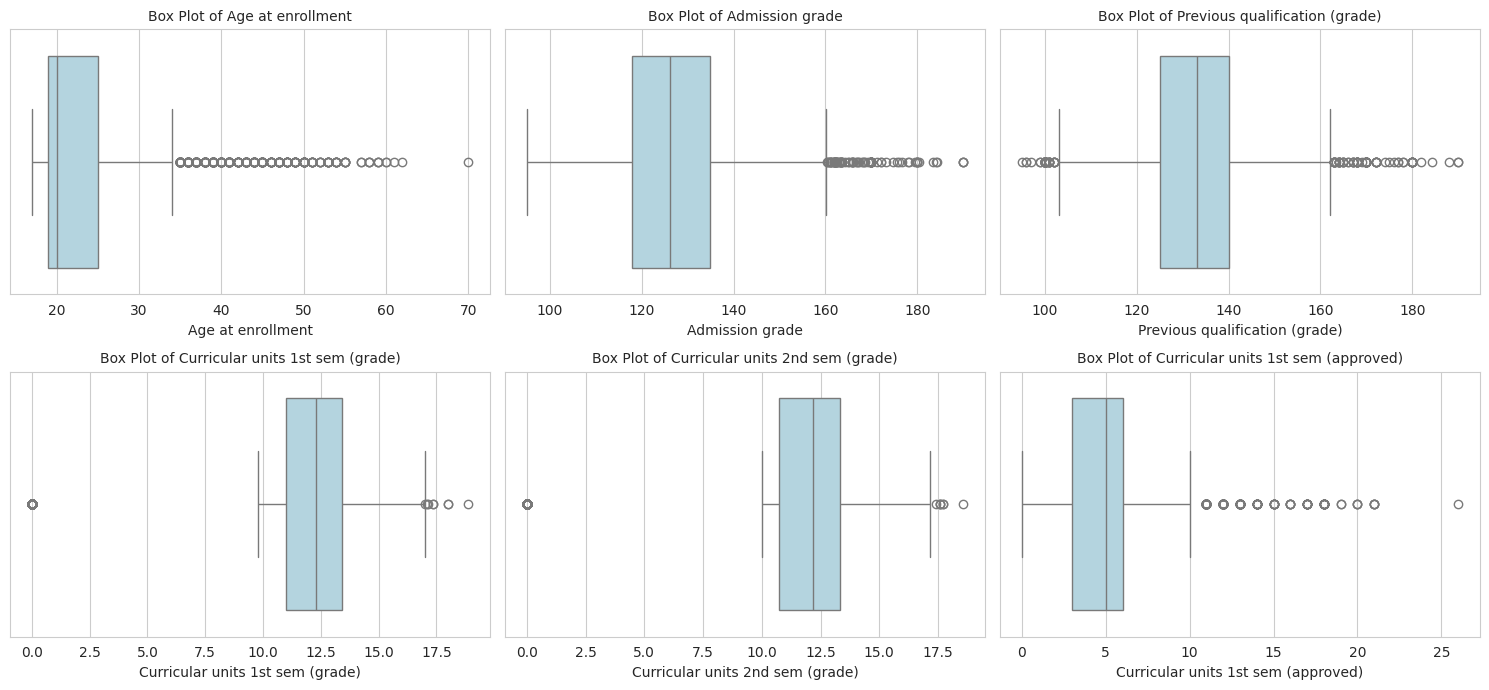

In [63]:
cont_cols = ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment',
             'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
             'Unemployment rate', 'Inflation rate', 'GDP']
count_cols = [c for c in df.columns if c.startswith('Curricular units') and 'grade' not in c]
check_cols = cont_cols + count_cols

Q1 = df[check_cols].quantile(0.25)
Q3 = df[check_cols].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
mask = (df[check_cols] < lower) | (df[check_cols] > upper)

outlier_summary = pd.DataFrame({
    'Jumlah': mask.sum(),
    'Persen': (mask.mean() * 100).round(2),
    'Batas Bawah': lower.round(2),
    'Batas Atas': upper.round(2)
}).sort_values('Jumlah', ascending=False)
display(outlier_summary)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flatten(), ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
                                    'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
                                    'Curricular units 1st sem (approved)']):
    sns.boxplot(x=df[col], ax=ax, color='lightblue')
    ax.set_title(f'Box Plot of {col}', fontsize=10)
plt.tight_layout()
plt.show()

In [64]:
# Apakah outlier usia membawa informasi terhadap target?
age_out = df['Age at enrollment'] > upper['Age at enrollment']
print('Proporsi Dropout pada outlier usia :', round((df.loc[age_out, 'Target'] == 'Dropout').mean() * 100, 1), '%')
print('Proporsi Dropout pada seluruh data :', round((df['Target'] == 'Dropout').mean() * 100, 1), '%')

# Penanganan: capping (winsorizing) pada tiga fitur; baris TIDAK dihapus
cap_cols = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)']
for c in cap_cols:
    df[c] = df[c].clip(lower=lower[c], upper=upper[c])

print('\nDimensi data setelah penanganan outlier :', df.shape)
display(df[cap_cols].describe().T.round(2))

Proporsi Dropout pada outlier usia : 53.7 %
Proporsi Dropout pada seluruh data : 32.1 %

Dimensi data setelah penanganan outlier : (4424, 37)


,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,22.46,5.41,17.0,19.0,20.0,25.0,34.00
Admission grade,4424.0,126.81,14.00,95.0,117.9,126.1,134.8,160.15
Previous qualification (grade),4424.0,132.50,12.59,102.5,125.0,133.1,140.0,162.50


## Data Transformation: Encoding

In [65]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_enc = df.copy()
df_enc['Target'] = le.fit_transform(df['Target'])
print('Pemetaan kelas target :', {c: int(i) for c, i in zip(le.classes_, le.transform(le.classes_))})

# Fitur kategorikal sudah berupa kode numerik dari sumber data
cat_code_cols = ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nationality',
                 "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
print('\nJumlah kategori unik per fitur kode:')
print(df_enc[cat_code_cols].nunique())

# Pembanding: One-Hot Encoding pada Marital status dan Course
df_onehot = pd.get_dummies(df_enc, columns=['Marital status', 'Course'], dtype=int)
print('\nDimensi Label Encoding :', df_enc.shape)
print('Dimensi One-Hot (Marital status & Course) :', df_onehot.shape)
display(df_enc.head(3).T.head(12))

Pemetaan kelas target : {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}

Jumlah kategori unik per fitur kode:
Marital status             6
Application mode          18
Course                    17
Previous qualification    17
Nationality               21
Mother's qualification    29
Father's qualification    34
Mother's occupation       32
Father's occupation       46
dtype: int64

Dimensi Label Encoding : (4424, 37)
Dimensi One-Hot (Marital status & Course) : (4424, 58)


,0,1,2
Marital status,1.0,1.0,1.0
Application mode,17.0,15.0,1.0
Application order,5.0,1.0,5.0
Course,171.0,9254.0,9070.0
Daytime/evening attendance,1.0,1.0,1.0
Previous qualification,1.0,1.0,1.0
Previous qualification (grade),122.0,160.0,122.0
Nationality,1.0,1.0,1.0
Mother's qualification,19.0,1.0,37.0
Father's qualification,12.0,3.0,37.0


## EDA: Distribusi Target

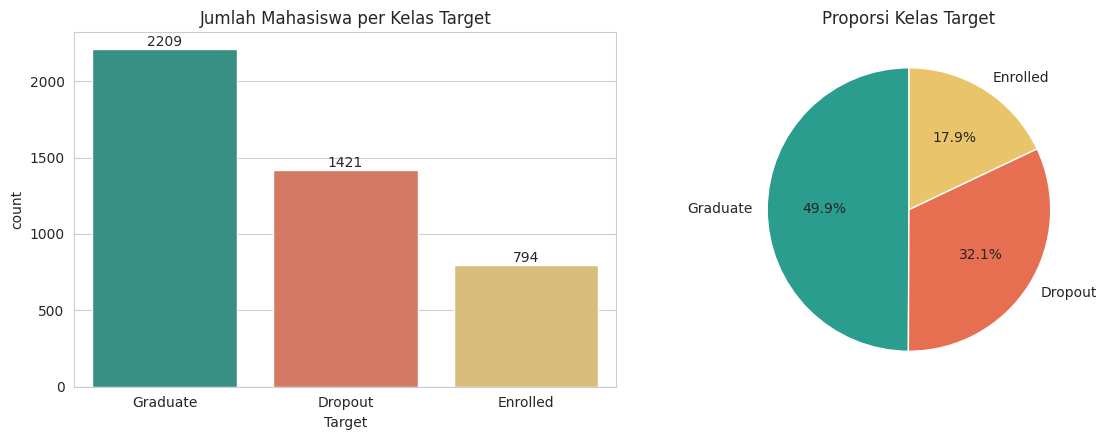

Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


In [66]:
order = df['Target'].value_counts().index
colors = {'Graduate': '#2a9d8f', 'Dropout': '#e76f51', 'Enrolled': '#e9c46a'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(x='Target', data=df, order=order, hue='Target', palette=colors, legend=False, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
axes[0].set_title('Jumlah Mahasiswa per Kelas Target')
axes[1].pie(df['Target'].value_counts()[order], labels=order, autopct='%1.1f%%',
            colors=[colors[o] for o in order], startangle=90)
axes[1].set_title('Proporsi Kelas Target')
plt.tight_layout()
plt.show()
print(df['Target'].value_counts(normalize=True).round(3))

## EDA: Histogram Fitur Numerik

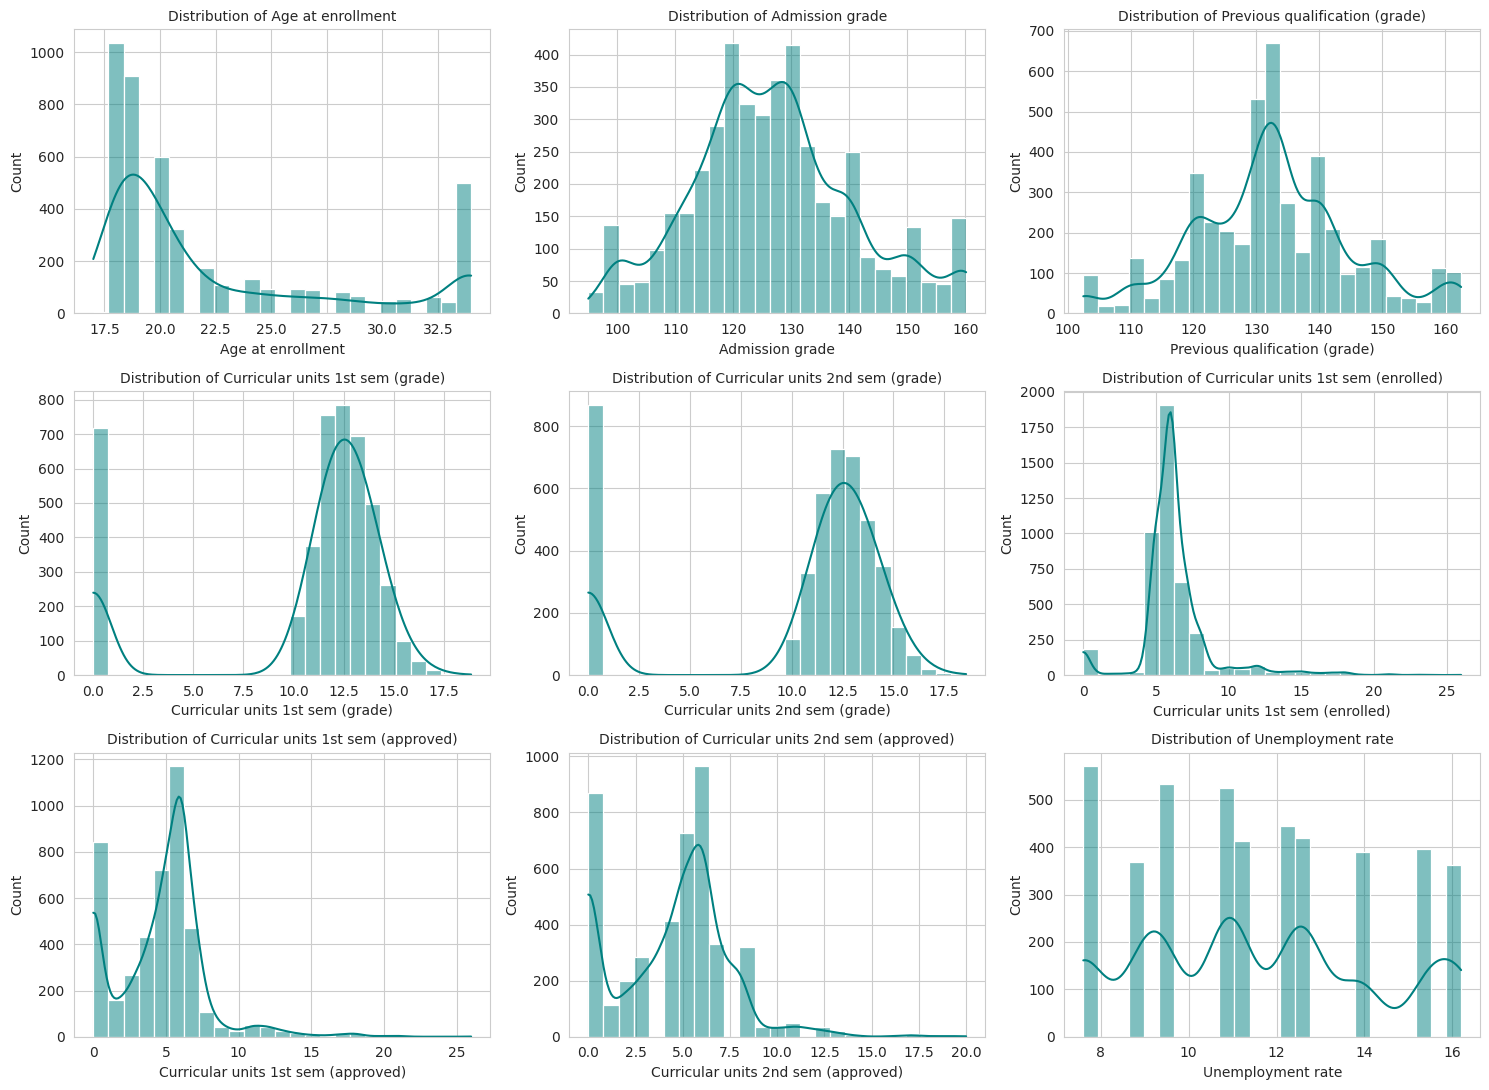

In [67]:
hist_cols = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
             'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
             'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (approved)',
             'Curricular units 2nd sem (approved)', 'Unemployment rate']
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flatten(), hist_cols):
    sns.histplot(df[col], kde=True, bins=25, color='teal', ax=ax)
    ax.set_title(f'Distribution of {col}', fontsize=10)
plt.tight_layout()
plt.show()

## ExDA: Fitur Numerik terhadap Target

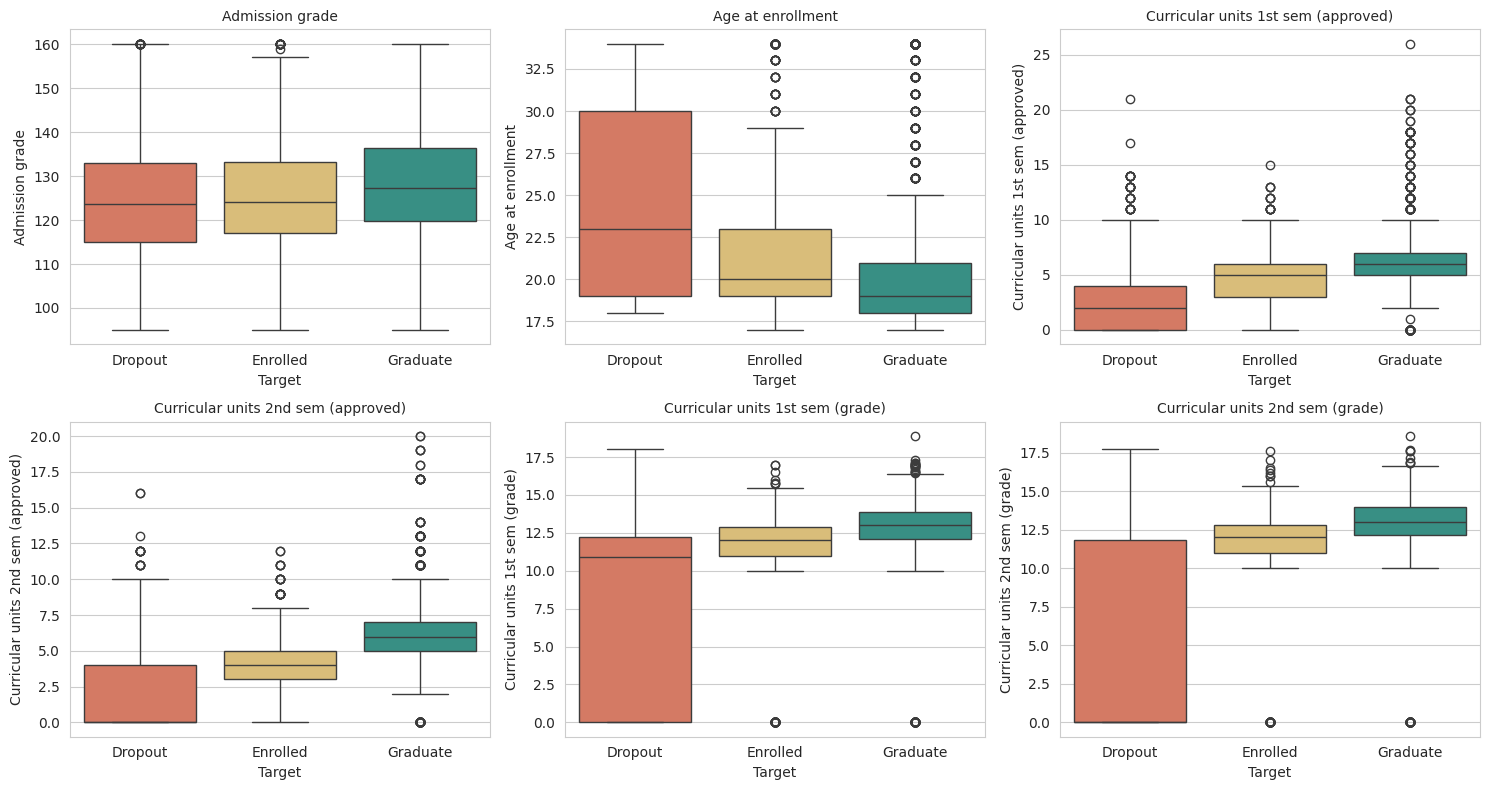

Target,Dropout,Enrolled,Graduate
Admission grade,124.81,125.36,128.62
Age at enrollment,24.74,21.88,21.20
Curricular units 1st sem (approved),2.55,4.32,6.23
Curricular units 2nd sem (approved),1.94,4.06,6.18
Curricular units 1st sem (grade),7.26,11.13,12.64
Curricular units 2nd sem (grade),5.90,11.12,12.70


In [68]:
box_cols = ['Admission grade', 'Age at enrollment',
            'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
            'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), box_cols):
    sns.boxplot(x='Target', y=col, data=df, order=['Dropout', 'Enrolled', 'Graduate'],
                hue='Target', palette=colors, legend=False, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()
display(df.groupby('Target')[box_cols].mean().round(2).T)

## ExDA: Fitur Biner terhadap Target

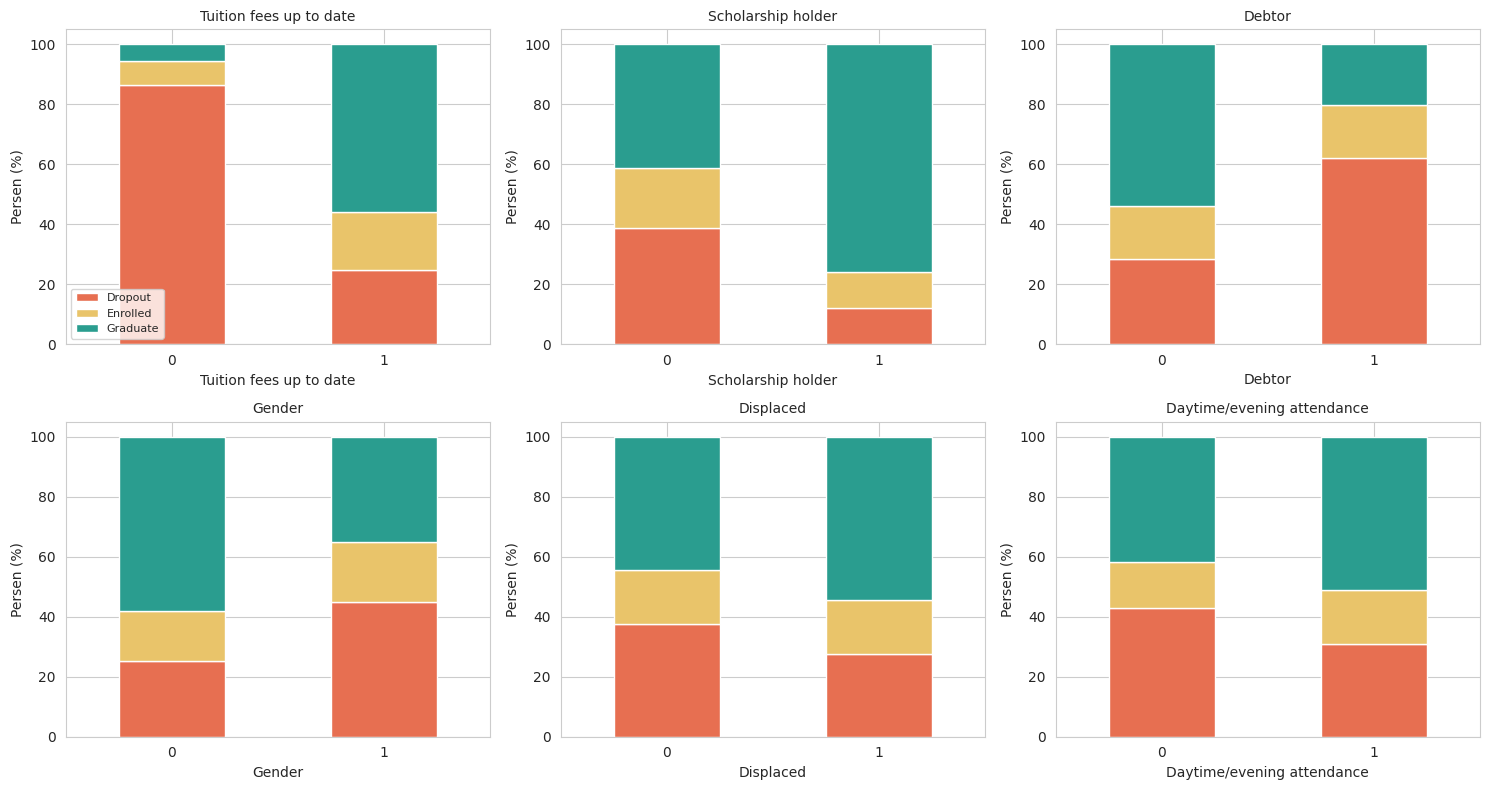

Persentase Dropout per nilai fitur biner (0 / 1):
                               0     1
Tuition fees up to date     86.6  24.7
Scholarship holder          38.7  12.2
Debtor                      28.3  62.0
Gender                      25.1  45.1
Displaced                   37.6  27.6
Daytime/evening attendance  42.9  30.8


In [69]:
bin_cols = ['Tuition fees up to date', 'Scholarship holder', 'Debtor', 'Gender', 'Displaced', 'Daytime/evening attendance']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
rates = {}
for ax, col in zip(axes.flatten(), bin_cols):
    ct = pd.crosstab(df[col], df['Target'], normalize='index')[['Dropout', 'Enrolled', 'Graduate']] * 100
    ct.plot(kind='bar', stacked=True, color=[colors[c] for c in ct.columns], ax=ax, rot=0, legend=False)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Persen (%)')
    rates[col] = ct['Dropout'].round(1)
axes[0, 0].legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()
print('Persentase Dropout per nilai fitur biner (0 / 1):')
print(pd.DataFrame(rates).T)

## ExDA: Dropout per Program Studi

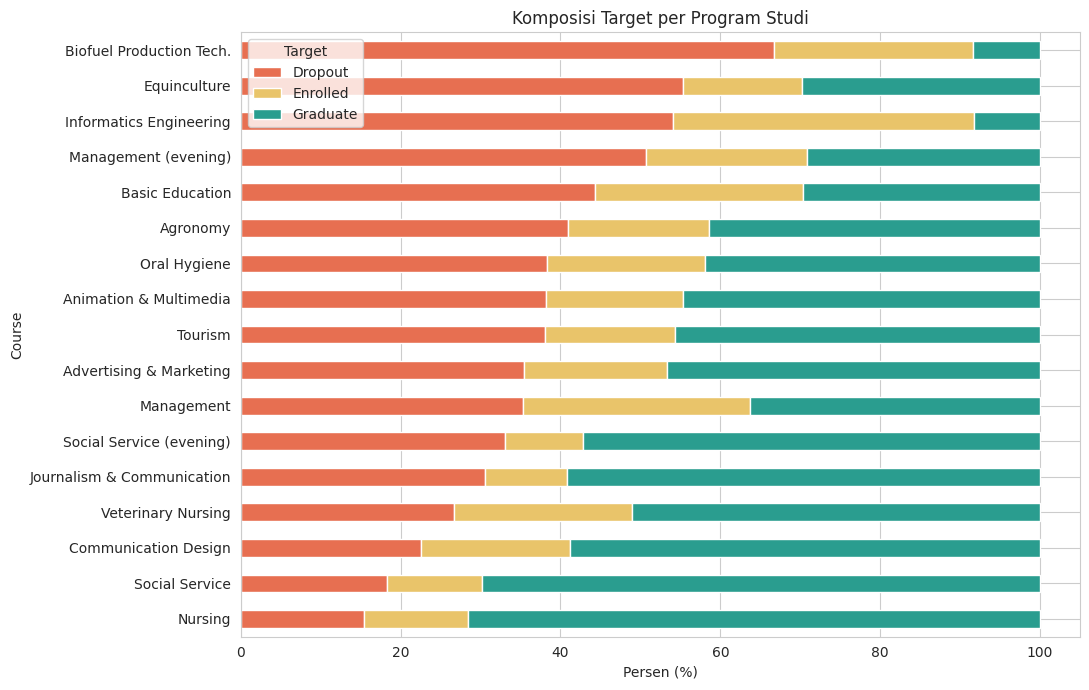

Course
Biofuel Production Tech.    66.7
Equinculture                55.3
Informatics Engineering     54.1
Management (evening)        50.7
Basic Education             44.3
Name: Dropout, dtype: float64


In [70]:
course_names = {33: 'Biofuel Production Tech.', 171: 'Animation & Multimedia', 8014: 'Social Service (evening)',
                9003: 'Agronomy', 9070: 'Communication Design', 9085: 'Veterinary Nursing',
                9119: 'Informatics Engineering', 9130: 'Equinculture', 9147: 'Management',
                9238: 'Social Service', 9254: 'Tourism', 9500: 'Nursing', 9556: 'Oral Hygiene',
                9670: 'Advertising & Marketing', 9773: 'Journalism & Communication',
                9853: 'Basic Education', 9991: 'Management (evening)'}
ct = pd.crosstab(df['Course'].map(course_names), df['Target'], normalize='index')[['Dropout', 'Enrolled', 'Graduate']] * 100
ct = ct.sort_values('Dropout')
ct.plot(kind='barh', stacked=True, color=[colors[c] for c in ct.columns], figsize=(11, 7))
plt.title('Komposisi Target per Program Studi')
plt.xlabel('Persen (%)')
plt.tight_layout()
plt.show()
print(ct['Dropout'].round(1).sort_values(ascending=False).head(5))

## ExDA: Matriks Korelasi

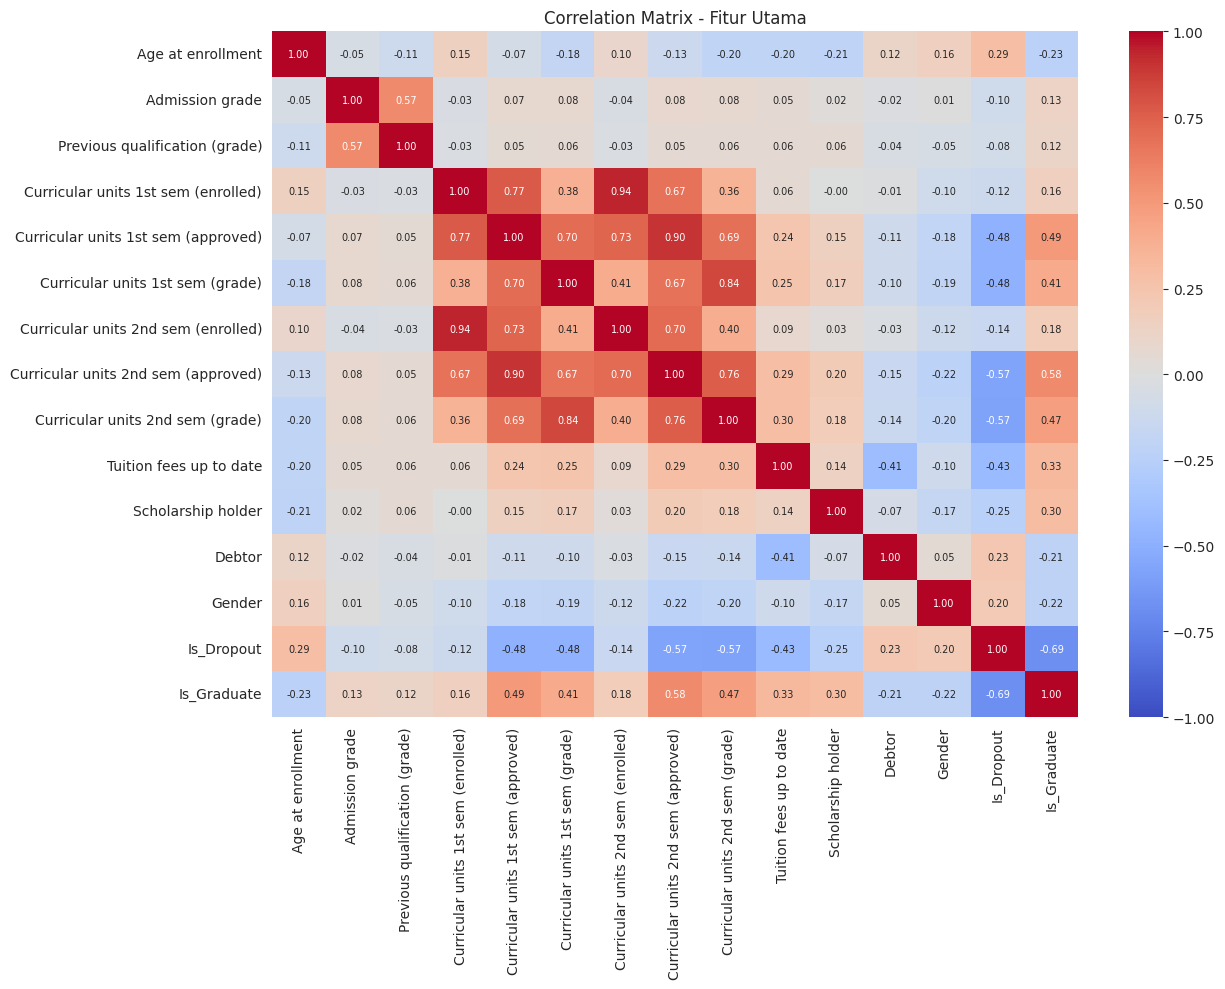

Pasangan fitur dengan |r| > 0.80:
Curricular units 1st sem (credited)  Curricular units 2nd sem (credited)    0.945
Curricular units 1st sem (enrolled)  Curricular units 2nd sem (enrolled)    0.943
Mother's occupation                  Father's occupation                    0.910
Curricular units 1st sem (approved)  Curricular units 2nd sem (approved)    0.904
Curricular units 1st sem (grade)     Curricular units 2nd sem (grade)       0.837
dtype: float64


In [71]:
corr_df = df_enc.drop(columns='Target').copy()
corr_df['Is_Dropout'] = (df_enc['Target'] == 0).astype(int)
corr_df['Is_Graduate'] = (df_enc['Target'] == 2).astype(int)

heat_cols = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
             'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)',
             'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)',
             'Tuition fees up to date', 'Scholarship holder', 'Debtor', 'Gender', 'Is_Dropout', 'Is_Graduate']
plt.figure(figsize=(13, 10))
sns.heatmap(corr_df[heat_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 7})
plt.title('Correlation Matrix - Fitur Utama')
plt.tight_layout()
plt.show()

# Pasangan fitur prediktor dengan korelasi tinggi (multikolinearitas)
cm = corr_df.drop(columns=['Is_Dropout', 'Is_Graduate']).corr().abs()
pairs = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool)).stack()
print('Pasangan fitur dengan |r| > 0.80:')
print(pairs[pairs > 0.80].sort_values(ascending=False).round(3))

## ExDA: Korelasi terhadap Target

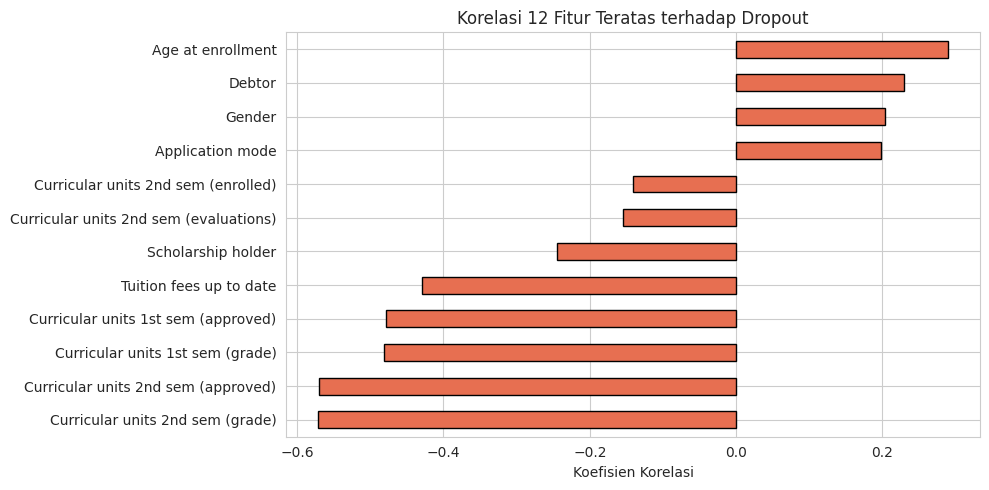

,Corr Dropout,Corr Graduate
Curricular units 2nd sem (grade),-0.572,0.473
Curricular units 2nd sem (approved),-0.570,0.577
Curricular units 1st sem (grade),-0.481,0.413
Curricular units 1st sem (approved),-0.479,0.492
Tuition fees up to date,-0.429,0.327
Age at enrollment,0.290,-0.233
Scholarship holder,-0.245,0.299
Debtor,0.229,-0.214
Gender,0.204,-0.217
Application mode,0.198,-0.209


In [72]:
feat = corr_df.drop(columns=['Is_Dropout', 'Is_Graduate'])
corr_drop = feat.corrwith(corr_df['Is_Dropout'])
corr_grad = feat.corrwith(corr_df['Is_Graduate'])
top = corr_drop.abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(10, 5))
corr_drop[top].sort_values().plot(kind='barh', color='#e76f51', edgecolor='black')
plt.title('Korelasi 12 Fitur Teratas terhadap Dropout')
plt.xlabel('Koefisien Korelasi')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Corr Dropout': corr_drop[top].round(3), 'Corr Graduate': corr_grad[top].round(3)}))

## Data Splitting: Memisahkan Fitur dan Target

In [73]:
X = df_enc.drop(columns='Target')
y = df_enc['Target']
print('Dimensi fitur X :', X.shape)
print('Dimensi target y:', y.shape)

Dimensi fitur X : (4424, 36)
Dimensi target y: (4424,)


## Data Splitting: Train dan Test

In [74]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Jumlah data total :', len(X))
print('Jumlah data latih :', len(x_train))
print('Jumlah data uji   :', len(x_test))
print('\nProporsi kelas (0=Dropout, 1=Enrolled, 2=Graduate):')
print(pd.DataFrame({'Total': y.value_counts(normalize=True).round(3),
                    'Latih': y_train.value_counts(normalize=True).round(3),
                    'Uji': y_test.value_counts(normalize=True).round(3)}))

Jumlah data total : 4424
Jumlah data latih : 3539
Jumlah data uji   : 885

Proporsi kelas (0=Dropout, 1=Enrolled, 2=Graduate):
        Total  Latih    Uji
Target                     
2       0.499  0.499  0.499
0       0.321  0.321  0.321
1       0.179  0.179  0.180


## Data Transformation: Standardisasi

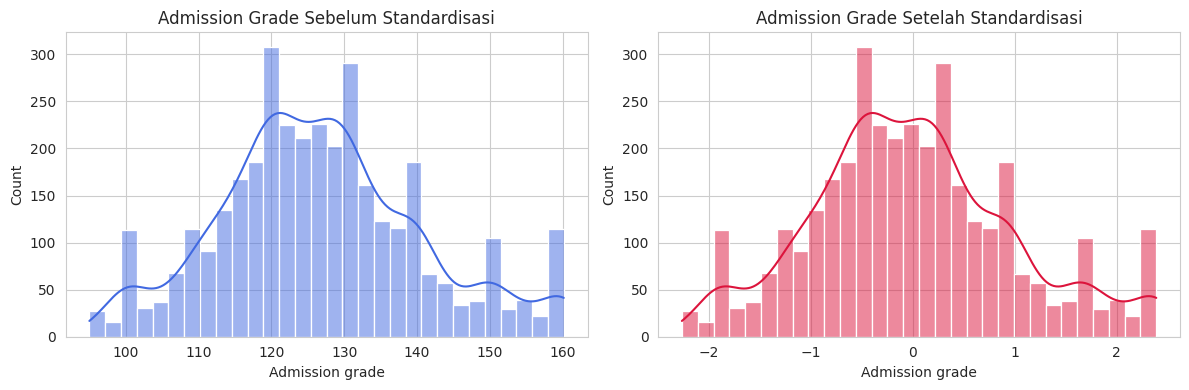

,Course,Admission grade,Age at enrollment,Curricular units 1st sem (grade)
mean,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


In [75]:
from sklearn.preprocessing import StandardScaler

# Seluruh fitur distandarisasi agar model berbasis jarak/margin (KNN, SVM, Logistic Regression)
# tidak didominasi fitur berskala besar seperti kode Course (33-9991)
scale_cols = X.columns.tolist()
scaler = StandardScaler()
x_train_s = x_train.copy()
x_test_s = x_test.copy()
x_train_s[scale_cols] = scaler.fit_transform(x_train[scale_cols])   # fit hanya pada data latih
x_test_s[scale_cols] = scaler.transform(x_test[scale_cols])         # data uji hanya di-transform

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(x_train['Admission grade'], kde=True, color='royalblue')
plt.title('Admission Grade Sebelum Standardisasi')
plt.subplot(1, 2, 2)
sns.histplot(x_train_s['Admission grade'], kde=True, color='crimson')
plt.title('Admission Grade Setelah Standardisasi')
plt.tight_layout()
plt.show()
display(x_train_s[['Course', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (grade)']].describe().loc[['mean', 'std']].round(3))

## Modelling: Melatih Model

In [76]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
import time

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}
for name, model in models.items():
    t0 = time.time()
    model.fit(x_train_s, y_train)
    print(f'{name:<20} selesai dilatih dalam {time.time() - t0:.2f} detik')

Logistic Regression  selesai dilatih dalam 0.41 detik
KNN                  selesai dilatih dalam 0.02 detik
Decision Tree        selesai dilatih dalam 0.12 detik
SVM (RBF)            selesai dilatih dalam 2.17 detik
Random Forest        selesai dilatih dalam 5.23 detik
Gradient Boosting    selesai dilatih dalam 5.47 detik


## Modelling: Evaluasi pada Data Uji

,Accuracy,Prec (macro),Rec (macro),F1 (macro),F1 (weighted),CV Acc (5-fold)
Random Forest,0.7774,0.7333,0.6873,0.6991,0.7626,0.7748
Gradient Boosting,0.7627,0.7093,0.6804,0.6896,0.7522,0.7739
Logistic Regression,0.7695,0.7106,0.6771,0.6850,0.7544,0.7674
SVM (RBF),0.7537,0.6958,0.6602,0.6700,0.7400,0.7598
Decision Tree,0.7322,0.6706,0.6453,0.6530,0.7207,0.7468
KNN,0.6791,0.5943,0.5768,0.5796,0.6628,0.6977


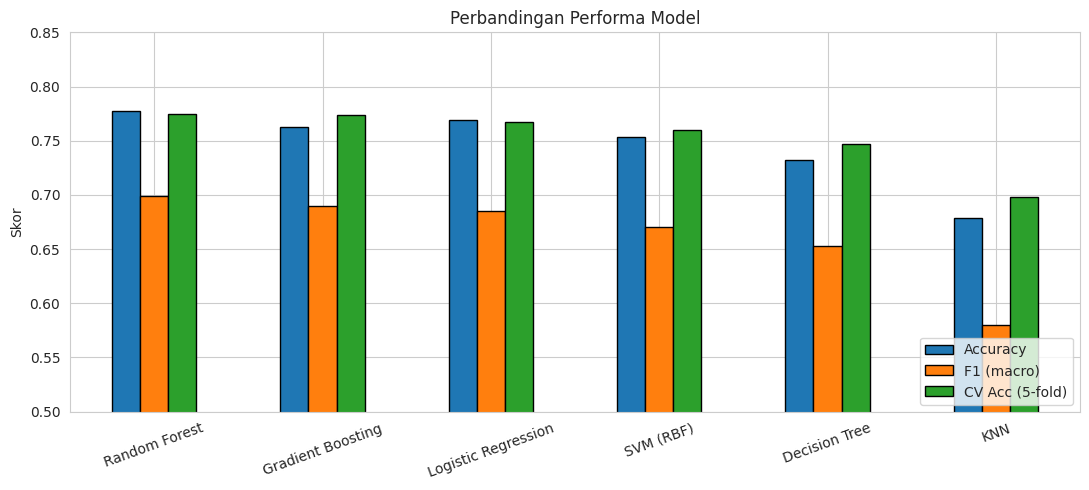

In [77]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
preds = {}
for name, model in models.items():
    pred = model.predict(x_test_s)
    preds[name] = pred
    rows[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Prec (macro)': precision_score(y_test, pred, average='macro'),
        'Rec (macro)': recall_score(y_test, pred, average='macro'),
        'F1 (macro)': f1_score(y_test, pred, average='macro'),
        'F1 (weighted)': f1_score(y_test, pred, average='weighted'),
        'CV Acc (5-fold)': cross_val_score(model, x_train_s, y_train, cv=skf, scoring='accuracy').mean(),
    }
df_results = pd.DataFrame(rows).T.sort_values('F1 (macro)', ascending=False)
display(df_results.round(4))

df_results[['Accuracy', 'F1 (macro)', 'CV Acc (5-fold)']].plot(kind='bar', figsize=(11, 5), rot=20, edgecolor='black')
plt.title('Perbandingan Performa Model')
plt.ylabel('Skor')
plt.ylim(0.5, 0.85)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Modelling: Random Forest dengan Penyeimbangan Kelas

In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Langsung gunakan hyperparameter terbaik yang sudah ditemukan sebelumnya
best_rf = RandomForestClassifier(
    class_weight='balanced',
    max_depth=20,
    max_features='log2',
    min_samples_leaf=4,
    n_estimators=300,
    random_state=42
)

# Latih model secara langsung
best_rf.fit(x_train_s, y_train)

pred_best = best_rf.predict(x_test_s)
print('Accuracy data uji setelah optimasi :', round(accuracy_score(y_test, pred_best), 4))
print('F1 macro data uji setelah optimasi :', round(f1_score(y_test, pred_best, average='macro'), 4))
print('(Sebelum diatur class_weight-nya    : Accuracy', round(df_results.loc['Random Forest', 'Accuracy'], 4),
      '| F1 macro', round(df_results.loc['Random Forest', 'F1 (macro)'], 4), ')')

Accuracy data uji setelah optimasi : 0.7503
F1 macro data uji setelah optimasi : 0.7016
(Sebelum diatur class_weight-nya    : Accuracy 0.7774 | F1 macro 0.6991 )


## Modelling: Optimasi Bobot Kelas (Random Forest)

In [79]:
from sklearn.metrics import recall_score

rec = pd.DataFrame({
    'RF Baseline': recall_score(y_test, preds['Random Forest'], average=None),
    'RF Balanced': recall_score(y_test, pred_best, average=None)},
    index=['Dropout', 'Enrolled', 'Graduate'])
display(rec.round(3))

,RF Baseline,RF Balanced
Dropout,0.761,0.694
Enrolled,0.365,0.560
Graduate,0.937,0.855


## Modelling: Classification Report dan Confusion Matrix

              precision    recall  f1-score   support

     Dropout      0.824     0.694     0.753       284
    Enrolled      0.466     0.560     0.509       159
    Graduate      0.831     0.855     0.843       442

    accuracy                          0.750       885
   macro avg      0.707     0.703     0.702       885
weighted avg      0.763     0.750     0.754       885



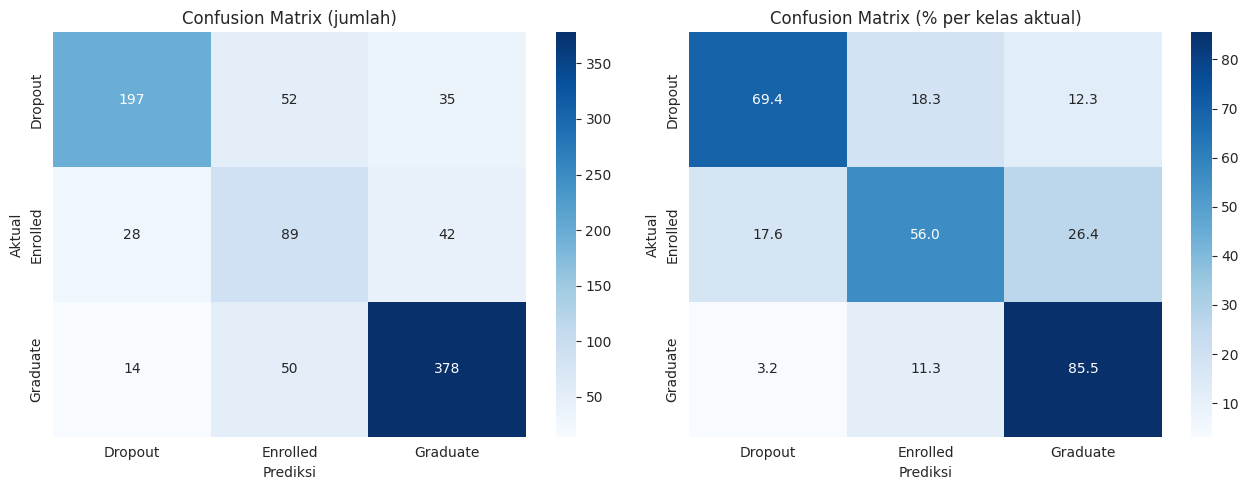

In [80]:
from sklearn.metrics import classification_report, confusion_matrix

labels = ['Dropout', 'Enrolled', 'Graduate']
print(classification_report(y_test, pred_best, target_names=labels, digits=3))

cm = confusion_matrix(y_test, pred_best)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title('Confusion Matrix (jumlah)')
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title('Confusion Matrix (% per kelas aktual)')
for ax in axes:
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
plt.tight_layout()
plt.show()

## Modelling: Feature Importance

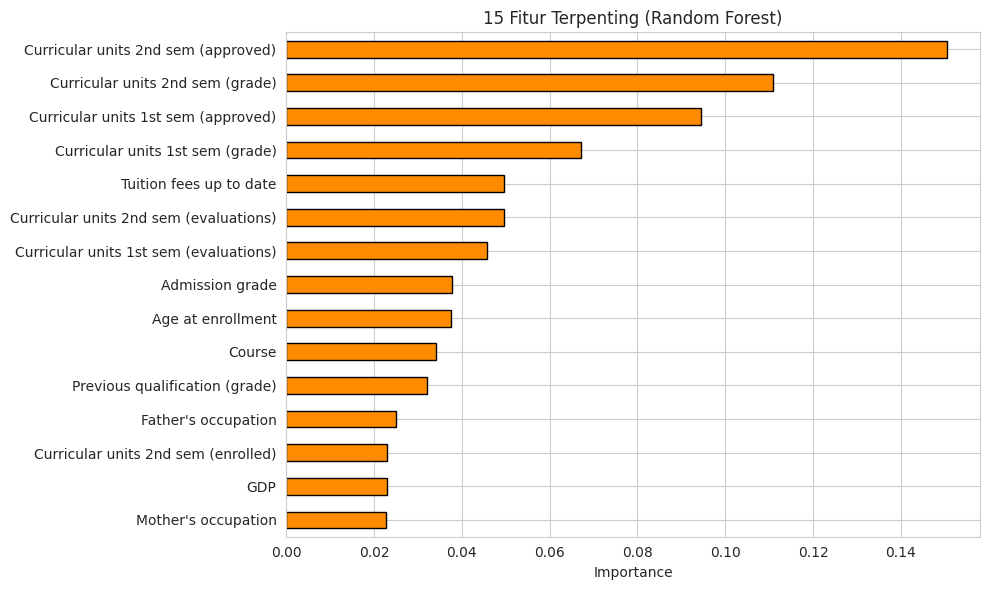

,0
Curricular units 2nd sem (approved),0.1505
Curricular units 2nd sem (grade),0.1108
Curricular units 1st sem (approved),0.0944
Curricular units 1st sem (grade),0.0671
Tuition fees up to date,0.0497
Curricular units 2nd sem (evaluations),0.0497
Curricular units 1st sem (evaluations),0.0458
Admission grade,0.0377
Age at enrollment,0.0376
Course,0.0341


In [81]:
imp = pd.Series(best_rf.feature_importances_, index=x_train_s.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
imp.head(15).sort_values().plot(kind='barh', color='darkorange', edgecolor='black')
plt.title('15 Fitur Terpenting (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()
display(imp.head(10).round(4))

## Model Persistence

In [82]:
import joblib

joblib.dump({'model': best_rf, 'scaler': scaler, 'label_encoder': le, 'features': list(X.columns)},
            'rf_dropout_model.joblib')
print("Model RF berhasil disimpan ke 'rf_dropout_model.joblib'!")

# Uji muat ulang dan prediksi 5 mahasiswa dari data uji
bundle = joblib.load('rf_dropout_model.joblib')
sample = x_test.head(5)
pred_sample = bundle['model'].predict(bundle['scaler'].transform(sample))
print('\nPrediksi :', list(bundle['label_encoder'].inverse_transform(pred_sample)))
print('Aktual   :', list(bundle['label_encoder'].inverse_transform(y_test.head(5))))

Model RF berhasil disimpan ke 'rf_dropout_model.joblib'!

Prediksi : ['Graduate', 'Graduate', 'Dropout', 'Graduate', 'Graduate']
Aktual   : ['Graduate', 'Graduate', 'Enrolled', 'Graduate', 'Graduate']
